# Экзаменационная задача №07. Оценка эффективности внедрения информационной системы (NPV, IRR, ROI)

**Дисциплина:** Экономика информатизации, лекция №8
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №07: ОЦЕНКА ЭФФЕКТИВНОСТИ ВНЕДРЕНИЯ ИНФОРМАЦИОННОЙ СИСТЕМЫ (NPV, IRR, ROI)
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №8)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Госучреждение думает о внедрении электронного документооборота. Нужно вложить 55 млн руб. и тратить 9 млн руб. в год.
Взамен экономится время сотрудников и бумага, меньше ошибок, процессы идут быстрее.
Вопрос: окупятся ли вложения и при каких условиях проект станет выгодным.

**Цель:** посчитать NPV, IRR, сроки окупаемости и ROI, проверить чувствительность и найти порог безубыточности.

Тема лекции №8: ROI, TEI, NPV, IRR, простой и дисконтированный срок окупаемости, амортизация и налог в денежном потоке,
неденежные выгоды в госсекторе.

## 2. Исходные данные

In [2]:
# 1.1. Инвестиции (год 0), млн руб.
dev, equipment, training = 35.0, 15.0, 5.0
# 1.2. Ежегодные затраты, млн руб.
licenses, support, admin = 3.0, 2.0, 4.0
# 1.3. Ежегодные выгоды, млн руб.
benefits = {"Экономия времени сотрудников": 8.0, "Снижение расходов на бумагу и печать": 2.0,
            "Сокращение ошибок": 3.0, "Ускорение процессов": 2.0}
non_monetary = 1.0      # рост удовлетворённости граждан (неденежная выгода)
H, r, tax, dep_years = 5, 0.10, 0.20, 5
pd.DataFrame({"Выгода, млн руб./год": benefits})

,"Выгода, млн руб./год"
Экономия времени сотрудников,8.00
Снижение расходов на бумагу и печать,2.00
Сокращение ошибок,3.00
Ускорение процессов,2.00


**Допущения:**
- Неденежную выгоду (удовлетворённость граждан, 1 млн руб.) в основной расчёт **не включаем**: живых денег она не приносит.
  Её влияние показано отдельным сценарием (подход TEI).
- Амортизируем только оборудование (15 млн руб. / 5 лет = 3 млн руб. в год), как сказано в условии. Разработка и обучение
  идут вложениями года 0 без налоговой экономии на амортизации (осторожная оценка). Вариант, где разработка учитывается
  как НМА, есть в чувствительности.
- Налог на прибыль 20 % берём с прироста прибыли (выгоды − затраты − амортизация).

## 3. Математическая модель

$$CF_t = (B_t - C_t - D_t)(1-T) + D_t,\qquad t=1..5;\qquad CF_0=-I$$
$$NPV=\sum_{t=0}^{5}\frac{CF_t}{(1+r)^t},\qquad NPV(IRR)=0,\qquad ROI=\frac{\sum_{t=1}^5 CF_t - I}{I}$$
$$PP:\ \sum_{k\le PP} CF_k=0,\qquad DPP:\ \sum_{k\le DPP}\frac{CF_k}{(1+r)^k}=0$$
Порог безубыточности по экономии времени $S^*$ находим из условия $NPV(S^*)=0$.

## 4. Реализация расчёта
### 4.1. Денежные потоки

In [3]:
def cash_flows(time_saving=benefits["Экономия времени сотрудников"], dev_cost=dev, rate_tax=tax,
               extra_benefit=0.0, amortize_dev=False):
    """Денежный поток проекта по годам (млн руб.)."""
    invest = dev_cost + equipment + training
    B = time_saving + sum(v for k, v in benefits.items() if k != "Экономия времени сотрудников") + extra_benefit
    C = licenses + support + admin
    D = equipment / dep_years + (dev_cost / dep_years if amortize_dev else 0)
    rows = [{"Год": 0, "Инвестиции": invest, "Выгоды": 0, "Затраты": 0, "Амортизация": 0, "Прибыль до налога": 0,
             "Налог": 0, "Чистая прибыль": 0, "CF": -invest}]
    for t in range(1, H + 1):
        ebt = B - C - D
        tx = max(ebt, 0) * rate_tax
        rows.append({"Год": t, "Инвестиции": 0, "Выгоды": B, "Затраты": C, "Амортизация": D, "Прибыль до налога": ebt,
                     "Налог": tx, "Чистая прибыль": ebt - tx, "CF": ebt - tx + D})
    return pd.DataFrame(rows).set_index("Год")

cf_df = cash_flows()
cf = cf_df["CF"].values
cf_df["PV (10%)"] = present_values(cf, r)
cf_df["Накопл. CF"] = cf_df["CF"].cumsum()
cf_df["Накопл. PV"] = cf_df["PV (10%)"].cumsum()
print(f"Инвестиции года 0: {dev}+{equipment}+{training} = {-cf[0]:.0f} млн руб.;  ежегодные затраты: {licenses+support+admin:.0f} млн руб.")
cf_df.round(2)

Инвестиции года 0: 35.0+15.0+5.0 = 55 млн руб.;  ежегодные затраты: 9 млн руб.


,Инвестиции,Выгоды,Затраты,Амортизация,Прибыль до налога,Налог,Чистая прибыль,CF,PV (10%),Накопл. CF,Накопл. PV
Год,,,,,,,,,,,
0,55.00,0.00,0.00,0.00,0.00,0.00,0.00,-55.00,-55.00,-55.00,-55.00
1,0.00,15.00,9.00,3.00,3.00,0.60,2.40,5.40,4.91,-49.60,-50.09
2,0.00,15.00,9.00,3.00,3.00,0.60,2.40,5.40,4.46,-44.20,-45.63
3,0.00,15.00,9.00,3.00,3.00,0.60,2.40,5.40,4.06,-38.80,-41.57
4,0.00,15.00,9.00,3.00,3.00,0.60,2.40,5.40,3.69,-33.40,-37.88
5,0.00,15.00,9.00,3.00,3.00,0.60,2.40,5.40,3.35,-28.00,-34.53


### 4.2. Показатели эффективности

In [4]:
NPV_ = npv(cf, r); IRR_ = irr(cf); PP_ = payback_period(cf); DPP_ = discounted_payback_period(cf, r)
ROI_ = (cf[1:].sum() - (-cf[0])) / (-cf[0])
PI_ = present_values(cf, r)[1:].sum() / -cf[0]
kpi = pd.DataFrame({"Показатель": ["NPV (r=10%), млн руб.", "IRR", "Простой срок окупаемости", "Дисконтированный срок окупаемости", "ROI за 5 лет", "Индекс доходности PI"],
                    "Значение": [f"{NPV_:.2f}", f"{IRR_:.1%}", "не окупается за 5 лет" if math.isinf(PP_) else f"{PP_:.2f} г.",
                                 "не окупается за 5 лет" if math.isinf(DPP_) else f"{DPP_:.2f} г.", f"{ROI_:.1%}", f"{PI_:.2f}"]})
print(f"Сумма CF за 5 лет = {cf[1:].sum():.1f} млн руб. < инвестиции {-cf[0]:.0f} млн руб. → IRR отрицательная")
kpi

Сумма CF за 5 лет = 27.0 млн руб. < инвестиции 55 млн руб. → IRR отрицательная


,Показатель,Значение
0,"NPV (r=10%), млн руб.",-34.53
1,IRR,-19.8%
2,Простой срок окупаемости,не окупается за 5 лет
3,Дисконтированный срок окупаемости,не окупается за 5 лет
4,ROI за 5 лет,-50.9%
5,Индекс доходности PI,0.37


### 4.3. Анализ чувствительности

In [5]:
rows = []
for rt in [0.08, 0.10, 0.14]:
    rows.append({"Фактор": "Ставка", "Значение": f"{rt:.0%}", "NPV, млн": npv(cash_flows()["CF"], rt)})
for k in [0.8, 1.0, 1.2]:
    rows.append({"Фактор": "Экономия времени", "Значение": f"{k-1:+.0%} ({8*k:.1f})", "NPV, млн": npv(cash_flows(time_saving=8 * k)["CF"], r)})
for k in [0.8, 1.0, 1.2]:
    rows.append({"Фактор": "Стоимость разработки", "Значение": f"{k-1:+.0%} ({35*k:.0f})", "NPV, млн": npv(cash_flows(dev_cost=35 * k)["CF"], r)})
rows += [{"Фактор": "Доп. сценарии", "Значение": "учесть неденежную выгоду 1 млн/год", "NPV, млн": npv(cash_flows(extra_benefit=non_monetary)["CF"], r)},
         {"Фактор": "Доп. сценарии", "Значение": "учреждение не платит налог на прибыль", "NPV, млн": npv(cash_flows(rate_tax=0)["CF"], r)},
         {"Фактор": "Доп. сценарии", "Значение": "разработка капитализирована (НМА, 5 лет)", "NPV, млн": npv(cash_flows(amortize_dev=True)["CF"], r)}]
sens = pd.DataFrame(rows)
sens["Вывод"] = np.where(sens["NPV, млн"] > 0, "эффективен", "убыточен")
sens.round(2)

,Фактор,Значение,"NPV, млн",Вывод
0,Ставка,8%,-33.44,убыточен
1,Ставка,10%,-34.53,убыточен
2,Ставка,14%,-36.46,убыточен
3,Экономия времени,-20% (6.4),-39.38,убыточен
4,Экономия времени,+0% (8.0),-34.53,убыточен
5,Экономия времени,+20% (9.6),-29.68,убыточен
6,Стоимость разработки,-20% (28),-27.53,убыточен
7,Стоимость разработки,+0% (35),-34.53,убыточен
8,Стоимость разработки,+20% (42),-41.53,убыточен
9,Доп. сценарии,учесть неденежную выгоду 1 млн/год,-31.50,убыточен


In [6]:
# Порог безубыточности по экономии времени
from utils.calculations import solve_for
S_star = solve_for(lambda s: npv(cash_flows(time_saving=s)["CF"], r), 0, 0, 100)
B_star = S_star + 7
print(f"Экономия времени для NPV = 0: {S_star:.2f} млн руб./год (сейчас 8, нужно +{S_star/8-1:.0%})")
print(f"Совокупные денежные выгоды при этом: {B_star:.2f} млн руб./год (сейчас 15)")
# Альтернативный порог: снижение инвестиций при текущих выгодах
I_star = present_values(cf, r)[1:].sum()
print(f"При текущих выгодах проект безубыточен, если инвестиции ≤ {I_star:.1f} млн руб. (сейчас 55, т.е. −{1-I_star/55:.0%})")

Экономия времени для NPV = 0: 19.39 млн руб./год (сейчас 8, нужно +142%)
Совокупные денежные выгоды при этом: 26.39 млн руб./год (сейчас 15)
При текущих выгодах проект безубыточен, если инвестиции ≤ 20.5 млн руб. (сейчас 55, т.е. −63%)


## 5. Визуализация результатов

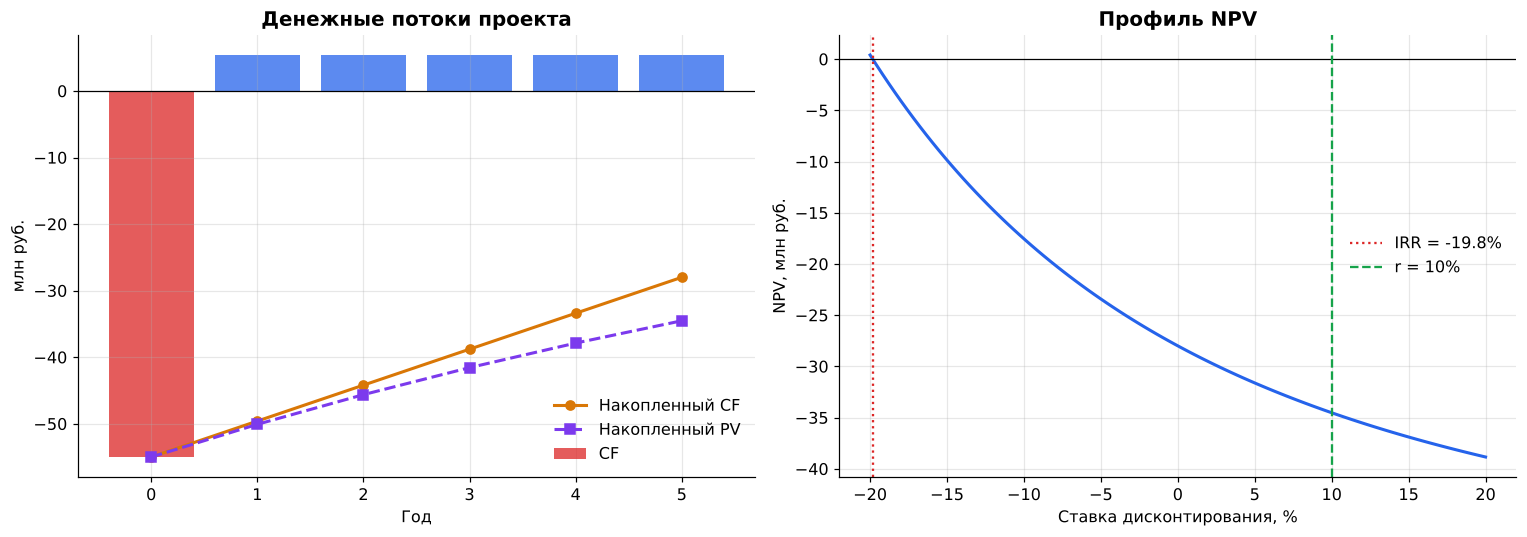

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.bar(cf_df.index, cf_df["CF"], color=[PALETTE[1]] + [PALETTE[0]] * H, alpha=0.75, label="CF")
ax.plot(cf_df.index, cf_df["Накопл. CF"], "o-", lw=2, color=PALETTE[3], label="Накопленный CF")
ax.plot(cf_df.index, cf_df["Накопл. PV"], "s--", lw=2, color=PALETTE[4], label="Накопленный PV")
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Год"); ax.set_ylabel("млн руб."); ax.set_title("Денежные потоки проекта")
ax.legend()
ax = axes[1]
rates = np.linspace(-0.2, 0.2, 100)
ax.plot(rates * 100, [npv(cf, x) for x in rates], lw=2)
ax.axhline(0, color="black", lw=0.8); ax.axvline(IRR_ * 100, color=PALETTE[1], ls=":", label=f"IRR = {IRR_:.1%}")
ax.axvline(10, color=PALETTE[2], ls="--", label="r = 10%")
ax.set_xlabel("Ставка дисконтирования, %"); ax.set_ylabel("NPV, млн руб."); ax.set_title("Профиль NPV"); ax.legend()
plt.tight_layout(); plt.show()

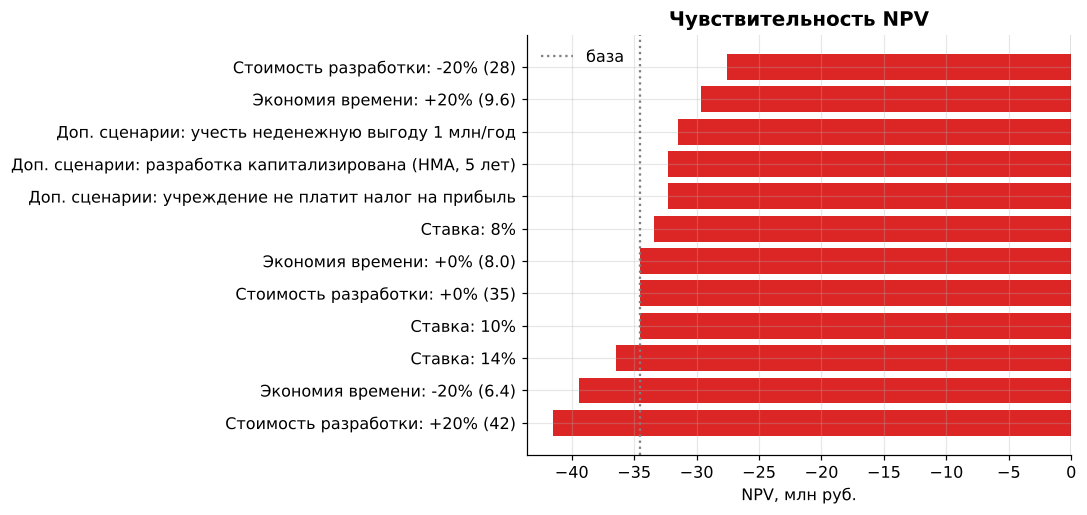

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
s = sens.copy(); s["Метка"] = s["Фактор"] + ": " + s["Значение"]
s = s.sort_values("NPV, млн")
ax.barh(s["Метка"], s["NPV, млн"], color=[PALETTE[1] if v < 0 else PALETTE[2] for v in s["NPV, млн"]])
ax.axvline(0, color="black", lw=0.8); ax.axvline(NPV_, color="gray", ls=":", label="база")
ax.set_xlabel("NPV, млн руб."); ax.set_title("Чувствительность NPV"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- Вложения **55 млн руб.**, ежегодные затраты 9 млн руб., денежные выгоды 15 млн руб. в год.
  До амортизации остаётся всего 6 млн руб. в год, чистый денежный поток **5,4 млн руб. в год**.
- **NPV около −34,5 млн руб.**: за 5 лет проект возвращает только 27 млн руб. из 55. IRR отрицательная (около −20 %),
  то есть не возвращаются даже вложенные деньги без учёта процентов. ROI около −51 %, проект не окупается за срок расчёта.
- **Чувствительность.** NPV не становится положительным ни при какой ставке от 8 до 14 %, ни при ±20 % экономии времени
  или стоимости разработки, ни с неденежной выгодой, ни без налога. Проблема в самой конструкции: годовой выигрыш слишком мал
  по сравнению с вложениями. Сильнее всего влияет стоимость разработки.
- **Порог безубыточности:** экономия времени должна быть около 19,4 млн руб. в год вместо 8 (в 2,4 раза больше),
  либо вложения не больше 20,5 млн руб. (на 63 % меньше).

## 7. Выводы и рекомендации

**Вывод:** при нынешних цифрах проект **невыгоден** (NPV < 0, IRR < 0, за 5 лет не окупается).
Для госучреждения его можно оправдать только как социально значимый, но тогда обосновывать нужно не через NPV,
а через качество услуг и скорость обработки обращений.

**Рекомендации**
1. *Уменьшить масштаб.* Взять готовую тиражируемую СЭД вместо заказной разработки. Если вложения снизятся примерно
   до 20 млн руб., проект выйдет в ноль.
2. *Внедрять по этапам.* Начать с подразделений, где документов больше всего и экономия времени максимальна.
3. *Закупать вместе* с другими учреждениями (единая платформа), чтобы разделить затраты на разработку.
4. *Точнее посчитать выгоды.* Замерить реальную экономию времени, ускорение процессов, меньшие штрафы за просрочки.
   Возможно, выгоды недооценены.
5. *Взять срок больше.* СЭД обычно живёт 7–10 лет. На 10 годах NPV лучше, но без снижения затрат всё равно отрицательный.

**Риски и что с ними делать**
| Риск | Что делать |
|---|---|
| Сотрудники сопротивляются и не пользуются системой | обучение, регламенты, отказ от параллельного бумажного документооборота |
| Разработка выйдет дороже | фиксированная цена контракта, приёмка по этапам |
| Выгоды не появятся (парадокс Солоу) | KPI по срокам обработки документов, контроль после внедрения |
| Лицензии подорожают | отечественное ПО, долгий договор |